In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path
from scipy.integrate import solve_ivp
from scipy.optimize import minimize

# -- Project root discovery -------------------------------------------------
PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.functions.membrane_model import N_FVM, membrane_ode, cost_k, D_model
from rfbmodel1D.parameters.params import D_params, k_params as k_ref, membraneparams

# -- Constants --------------------------------------------------------------
L       = 120e-6                              # membrane thickness [m]
DX      = L / N_FVM
X_NODES = (np.arange(N_FVM) + 0.5) * DX
DATA    = PROJECT_ROOT / 'data' / 'experimental'

# -- Experiment definitions -------------------------------------------------
EXPS = [
    dict(label='Dry N2/VS sorption',
         file='DRY_VS_sorption_Hwang.csv',
         a_left=0.0, a_right=1.0, lam_0=2.0,
         lc=dict(state='vapor',  mode='desorption'),
         rc=dict(state='vapor',  mode='sorption')),
    dict(label='Dry N2/VS desorption',
         file='DRY_VS_desorption_Hwang.csv',
         a_left=0.0, a_right=1.0, lam_0=14.0,
         lc=dict(state='vapor',  mode='desorption'),
         rc=dict(state='vapor',  mode='sorption')),
    dict(label='Dry N2/LS desorption',
         file='DRY_LS_desorption_Hwang.csv',
         a_left=0.0, a_right=3.0, lam_0=21.0,
         lc=dict(state='vapor',  mode='desorption'),
         rc=dict(state='liquid', mode='desorption')),
    dict(label='LS/VS steady state (Zhang 2008)',
         file='LS_VS_Zhang.csv',
         a_left=3.0, a_right=1.0, lam_0=22.0, t_final=500,
         lc=dict(state='liquid', mode='desorption'),
         rc=dict(state='vapor',  mode='desorption')),
    dict(label='LS/VS steady state (Hwang 2013)',
         file='LS_VS_desorption_Hwang.csv',
         a_left=3.0, a_right=1.0, lam_0=22.0, t_final=500,
         lc=dict(state='liquid', mode='desorption'),
         rc=dict(state='vapor',  mode='desorption')),
]

# -- k parameter index map --------------------------------------------------
K_NAMES = {0: 'k_vw_sorp', 1: 'k_vw_desorp', 2: 'k_lw_sorp', 3: 'k_lw_desorp'}
K_IDX   = {
    ('vapor',  'sorption'):   0,
    ('vapor',  'desorption'): 1,
    ('liquid', 'sorption'):   2,
    ('liquid', 'desorption'): 3,
}

# -- Helper functions -------------------------------------------------------
def _active_indices(lc, rc):
    return sorted({K_IDX[(c['state'], c['mode'])] for c in (lc, rc) if c['state'] == 'vapor'})

def _load_exp(exp):
    df   = pd.read_csv(DATA / exp['file'])
    lam0 = np.ones(N_FVM) * exp['lam_0']
    if 'time_seconds' in df.columns:
        t_last = sorted(df['time_seconds'].unique())[-1]
        sub    = df[df['time_seconds'] == t_last].sort_values('normalized_thickness')
        t_fit  = [t_last]
    else:
        sub   = df.sort_values('normalized_thickness')
        t_fit = [exp['t_final']]
    col = next(c for c in sub.columns if 'water' in c.lower())
    return 0, t_fit, lam0, [sub['normalized_thickness'].values * L], [sub[col].values]

def fit_exp(exp):
    t0, t_fit, lam0, x_lists, lam_lists = _load_exp(exp)
    active = _active_indices(exp['lc'], exp['rc'])

    def _cost(x):
        k_full = list(k_ref)
        for i, v in zip(active, x):
            k_full[i] = v
        return np.sum(cost_k(k_full, D_params, t_fit, x_lists, lam_lists,
                             lam0, t0, exp['a_left'], exp['a_right'],
                             exp['lc'], exp['rc'], DX) ** 2)

    result = minimize(_cost, x0=[k_ref[i] for i in active],
                      bounds=[(1e-11, 1e-2)] * len(active))
    k_opt = list(k_ref)
    for i, v in zip(active, result.x):
        k_opt[i] = v
    return t0, t_fit, lam0, x_lists, lam_lists, active, result, k_opt

def print_biot(sol, exp, k_opt):
    """Effective diffusivity, effective interfacial mass-transfer coefficient,
    and Biot number for the fitted profile (moved from validate_sorption.py).
    Bi = k_eff * L / D_eff: Bi >> 1 means interfacial transfer, not internal
    diffusion, is the bottleneck.
    """
    lambda_sim = sol.y[:, 0]
    D          = D_model(lambda_sim, params=D_params)
    D_eff      = L / (np.sum(1 / D) * DX)
    V_w        = float(membraneparams.V_w)
    V_m_dry    = float(membraneparams.V_m)
    k_eff_inv  = 0.0
    for side, lam in (('lc', float(lambda_sim[0])), ('rc', float(lambda_sim[-1]))):
        c = exp[side]
        if c['state'] == 'vapor':
            idx        = K_IDX[(c['state'], c['mode'])]
            k_val      = float(k_opt[idx])
            weight     = lam * V_w / (lam * V_w + V_m_dry)
            k_weighted = k_val * weight
            if k_weighted > 0.0:
                print(f"  {side} boundary: lambda={lam:.2f}, f_v={weight:.4f}, "
                      f"k={k_val:.4e} m/s, k_weighted={k_weighted:.4e} m/s")
                k_eff_inv += 1.0 / k_weighted
    k_eff = 1.0 / k_eff_inv if k_eff_inv > 0 else 0.0
    biot  = k_eff * L / D_eff
    print(f"  D_eff = {D_eff:.4e} m2/s   k_eff = {k_eff:.4e} m/s   Biot = {biot:.4f}")

def pub_axes(ax):
    """Apply publication style to ax."""
    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.tick_params(which='both', direction='in', top=True, right=True)

# -- Cache for combined plot ------------------------------------------------
_results = {}

print('Project root :', PROJECT_ROOT)
print('Data dir     :', DATA)
print(f'N_FVM = {N_FVM}   L = {L*1e6:.0f} µm')

Project root : C:\Users\jbvba\MSC RFB\RFBmodel1D_PC\rfbmodel1D
Data dir     : C:\Users\jbvba\MSC RFB\RFBmodel1D_PC\rfbmodel1D\data\experimental
N_FVM = 50   L = 120 µm


  k_vw_sorp            = 4.1767e-06  m/s
  k_vw_desorp          = 2.3885e-05  m/s
  RMSE(λ) = 0.5780
  APE(λ)  = 6.99 %
  lc boundary: lambda=3.43, f_v=0.1013, k=2.3885e-05 m/s, k_weighted=2.4203e-06 m/s
  rc boundary: lambda=8.35, f_v=0.2155, k=4.1767e-06 m/s, k_weighted=9.0026e-07 m/s
  D_eff = 1.1494e-10 m2/s   k_eff = 6.5619e-07 m/s   Biot = 0.6851


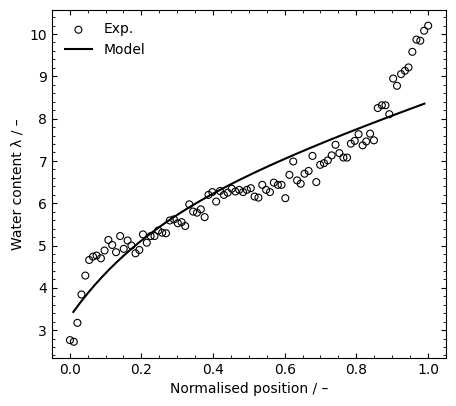

In [2]:
# -- Experiment 0: DRY/VS sorption (Hwang 2013) ----------------------------
exp = EXPS[0]
t0, t_fit, lam0, x_lists, lam_lists, active, result, k_opt = fit_exp(exp)

for i, v in zip(active, result.x):
    print(f'  {K_NAMES[i]:<20} = {v:.4e}  m/s')
lam_exp   = np.concatenate(lam_lists)
residuals = cost_k(k_opt, D_params, t_fit, x_lists, lam_lists, lam0, t0,
                   exp['a_left'], exp['a_right'], exp['lc'], exp['rc'], DX)
print(f'  RMSE(λ) = {np.sqrt(result.fun / len(lam_exp)):.4f}')
print(f'  APE(λ)  = {100 * np.mean(np.abs(residuals / lam_exp)):.2f} %')

sol = solve_ivp(membrane_ode, (t0, t_fit[-1]), lam0,
                args=(exp['a_left'], exp['a_right'], exp['lc'], exp['rc'],
                      DX, D_params, k_opt, 1.0),
                method='BDF', t_eval=t_fit)
print_biot(sol, exp, k_opt)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(x_lists[0] / L, lam_lists[0],
           s=25, facecolors='none', edgecolors='k', linewidths=0.8, zorder=5, label='Exp.')
if sol.success:
    ax.plot(X_NODES / L, sol.y[:, 0], color='k', lw=1.5, zorder=4, label='Model')
ax.set_xlabel('Normalised position / –')
ax.set_ylabel('Water content λ / –')
#ax.set_ylim(0, 22)
ax.legend(frameon=False)
pub_axes(ax)
plt.tight_layout(pad=0.5)
out = PROJECT_ROOT / 'figures' / 'diffusivity_k_exp0.pdf'
out.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out, bbox_inches='tight')
plt.show()
_results[0] = dict(sol=sol, x_lists=x_lists, lam_lists=lam_lists, exp=exp)

  k_vw_sorp            = 4.6008e-06  m/s
  k_vw_desorp          = 8.0964e-05  m/s
  RMSE(λ) = 0.2794
  APE(λ)  = 4.31 %
  lc boundary: lambda=2.33, f_v=0.0713, k=8.0964e-05 m/s, k_weighted=5.7705e-06 m/s
  rc boundary: lambda=8.40, f_v=0.2165, k=4.6008e-06 m/s, k_weighted=9.9624e-07 m/s
  D_eff = 1.0172e-10 m2/s   k_eff = 8.4956e-07 m/s   Biot = 1.0022


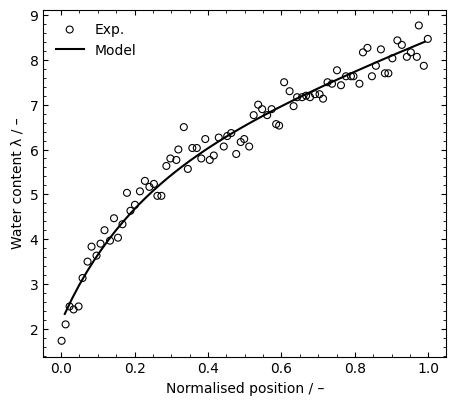

In [3]:
# -- Experiment 1: DRY/VS desorption (Hwang 2013) --------------------------
exp = EXPS[1]
t0, t_fit, lam0, x_lists, lam_lists, active, result, k_opt = fit_exp(exp)

for i, v in zip(active, result.x):
    print(f'  {K_NAMES[i]:<20} = {v:.4e}  m/s')
lam_exp   = np.concatenate(lam_lists)
residuals = cost_k(k_opt, D_params, t_fit, x_lists, lam_lists, lam0, t0,
                   exp['a_left'], exp['a_right'], exp['lc'], exp['rc'], DX)
print(f'  RMSE(λ) = {np.sqrt(result.fun / len(lam_exp)):.4f}')
print(f'  APE(λ)  = {100 * np.mean(np.abs(residuals / lam_exp)):.2f} %')

sol = solve_ivp(membrane_ode, (t0, t_fit[-1]), lam0,
                args=(exp['a_left'], exp['a_right'], exp['lc'], exp['rc'],
                      DX, D_params, k_opt, 1.0),
                method='BDF', t_eval=t_fit)
print_biot(sol, exp, k_opt)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(x_lists[0] / L, lam_lists[0],
           s=25, facecolors='none', edgecolors='k', linewidths=0.8, zorder=5, label='Exp.')
if sol.success:
    ax.plot(X_NODES / L, sol.y[:, 0], color='k', lw=1.5, zorder=4, label='Model')
ax.set_xlabel('Normalised position / –')
ax.set_ylabel('Water content λ / –')
ax.legend(frameon=False)
pub_axes(ax)
#ax.set_ylim(0, 22)
plt.tight_layout(pad=0.5)
out = PROJECT_ROOT / 'figures' / 'diffusivity_k_exp1.pdf'
out.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out, bbox_inches='tight')
plt.show()
_results[1] = dict(sol=sol, x_lists=x_lists, lam_lists=lam_lists, exp=exp)

  k_vw_desorp          = 1.7563e-04  m/s
  RMSE(λ) = 0.4713
  APE(λ)  = 3.72 %
  lc boundary: lambda=3.45, f_v=0.1019, k=1.7563e-04 m/s, k_weighted=1.7899e-05 m/s
  D_eff = 2.3605e-10 m2/s   k_eff = 1.7899e-05 m/s   Biot = 9.0993


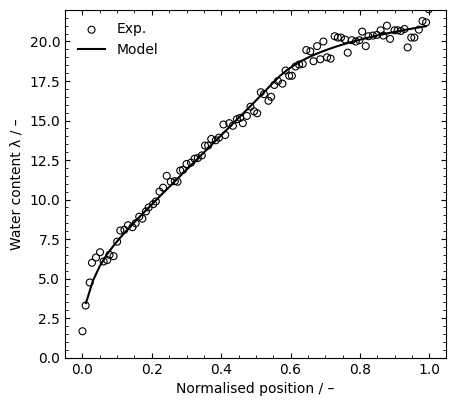

In [4]:
# -- Experiment 2: DRY/LS desorption (Hwang 2013) --------------------------
exp = EXPS[2]
t0, t_fit, lam0, x_lists, lam_lists, active, result, k_opt = fit_exp(exp)

for i, v in zip(active, result.x):
    print(f'  {K_NAMES[i]:<20} = {v:.4e}  m/s')
lam_exp   = np.concatenate(lam_lists)
residuals = cost_k(k_opt, D_params, t_fit, x_lists, lam_lists, lam0, t0,
                   exp['a_left'], exp['a_right'], exp['lc'], exp['rc'], DX)
print(f'  RMSE(λ) = {np.sqrt(result.fun / len(lam_exp)):.4f}')
print(f'  APE(λ)  = {100 * np.mean(np.abs(residuals / lam_exp)):.2f} %')

sol = solve_ivp(membrane_ode, (t0, t_fit[-1]), lam0,
                args=(exp['a_left'], exp['a_right'], exp['lc'], exp['rc'],
                      DX, D_params, k_opt, 21),
                method='BDF', t_eval=t_fit)
print_biot(sol, exp, k_opt)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(x_lists[0] / L, lam_lists[0],
           s=25, facecolors='none', edgecolors='k', linewidths=0.8, zorder=5, label='Exp.')
if sol.success:
    ax.plot(X_NODES / L, sol.y[:, 0], color='k', lw=1.5, zorder=4, label='Model')
ax.set_xlabel('Normalised position / –')
ax.set_ylabel('Water content λ / –')
ax.legend(frameon=False)
pub_axes(ax)
ax.set_ylim(0, 22)
plt.tight_layout(pad=0.5)
out = PROJECT_ROOT / 'figures' / 'diffusivity_k_exp2.pdf'
out.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out, bbox_inches='tight')
#plt.show()
_results[2] = dict(sol=sol, x_lists=x_lists, lam_lists=lam_lists, exp=exp)

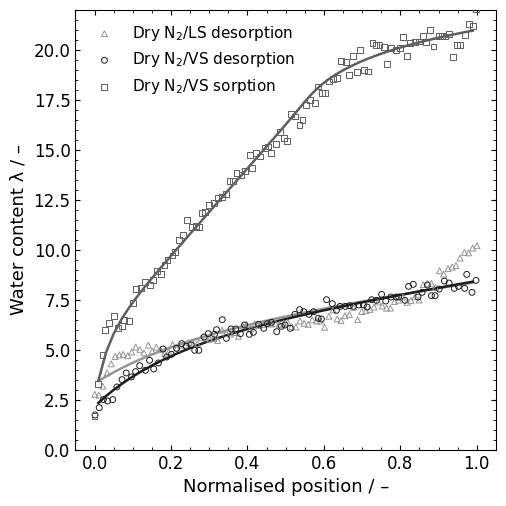

In [5]:
# -- Combined plot: Experiments 0–2 (reuses results from cells above) -------
cmap    = plt.cm.Greys
colors  = [cmap(0.5), cmap(0.9), cmap(0.7)]   # light grey -> medium -> dark grey
markers = ['^', 'o', 's']
FSIZE   = 13   # axis label / tick font size
labels  = [ r'Dry N$_2$/LS desorption', r'Dry N$_2$/VS desorption', r'Dry N$_2$/VS sorption' ]
fig, ax = plt.subplots(figsize=(5, 5))
for idx in range(3):
    r    = _results[idx]
    sol, x_lists, lam_lists, exp_i = r['sol'], r['x_lists'], r['lam_lists'], r['exp']
    c    = colors[idx]
    ax.scatter(x_lists[0] / L, lam_lists[0],
               s=18, marker=markers[idx], facecolors='none', edgecolors=c,
               linewidths=0.7, zorder=5, label=labels[idx])
    if sol.success:
        ax.plot(X_NODES / L, sol.y[:, 0], color=c, lw=1.8, zorder=4)

ax.set_xlabel('Normalised position / –', fontsize=FSIZE)
ax.set_ylabel('Water content λ / –', fontsize=FSIZE)
ax.set_ylim(0, 22)
ax.tick_params(labelsize=FSIZE - 1)
ax.legend(frameon=False, fontsize=FSIZE - 2)
pub_axes(ax)
plt.tight_layout(pad=0.5)
out = PROJECT_ROOT / 'figures' / 'diffusivity_k_exp0_2_combined.pdf'
out.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out, bbox_inches='tight')
plt.show()

  k_vw_desorp          = 1.0000e-02  m/s
  RMSE(λ) = 2.8180
  APE(λ)  = 17.52 %
  rc boundary: lambda=13.80, f_v=0.3122, k=1.0000e-02 m/s, k_weighted=3.1224e-03 m/s
  D_eff = 2.2178e-10 m2/s   k_eff = 3.1224e-03 m/s   Biot = 1689.4309


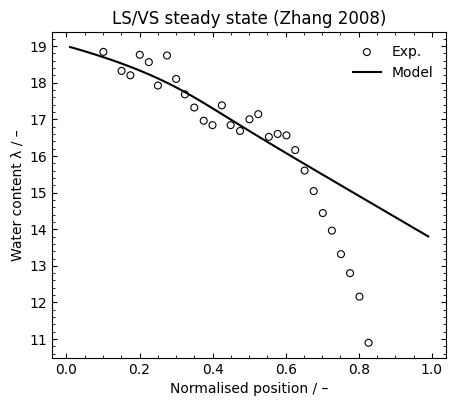

In [6]:
# -- Experiment 3: LS/VS steady state (Zhang 2008) -------------------------
exp = EXPS[3]
t0, t_fit, lam0, x_lists, lam_lists, active, result, k_opt = fit_exp(exp)

for i, v in zip(active, result.x):
    print(f'  {K_NAMES[i]:<20} = {v:.4e}  m/s')
lam_exp   = np.concatenate(lam_lists)
residuals = cost_k(k_opt, D_params, t_fit, x_lists, lam_lists, lam0, t0,
                   exp['a_left'], exp['a_right'], exp['lc'], exp['rc'], DX)
print(f'  RMSE(λ) = {np.sqrt(result.fun / len(lam_exp)):.4f}')
print(f'  APE(λ)  = {100 * np.mean(np.abs(residuals / lam_exp)):.2f} %')

sol = solve_ivp(membrane_ode, (t0, t_fit[-1]), lam0,
                args=(exp['a_left'], exp['a_right'], exp['lc'], exp['rc'],
                      DX, D_params, k_opt, 19),
                method='BDF', t_eval=t_fit)
print_biot(sol, exp, k_opt)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(x_lists[0] / L, lam_lists[0],
           s=25, facecolors='none', edgecolors='k', linewidths=0.8, zorder=5, label='Exp.')
if sol.success:
    ax.plot(X_NODES / L, sol.y[:, 0], color='k', lw=1.5, zorder=4, label='Model')
ax.set_xlabel('Normalised position / –')
ax.set_ylabel('Water content λ / –')
ax.set_title(exp['label'])
ax.legend(frameon=False)
pub_axes(ax)
plt.tight_layout(pad=0.5)
out = PROJECT_ROOT / 'figures' / 'diffusivity_k_exp3.pdf'
out.parent.mkdir(parents=True, exist_ok=True)
#plt.savefig(out, bbox_inches='tight')
plt.show()

  k_vw_desorp          = 1.0000e-11  m/s
  RMSE(λ) = 0.9142
  APE(λ)  = 3.44 %
  rc boundary: lambda=23.00, f_v=0.4307, k=1.0000e-11 m/s, k_weighted=4.3068e-12 m/s
  D_eff = 3.5598e-09 m2/s   k_eff = 4.3068e-12 m/s   Biot = 0.0000


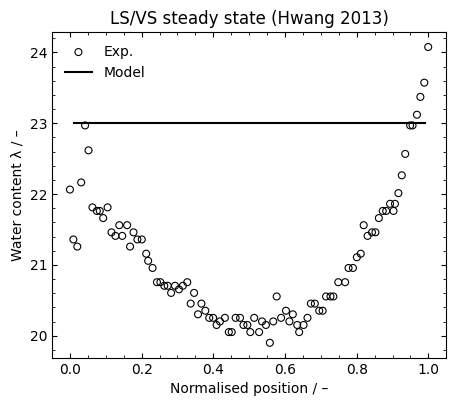

In [7]:
# -- Experiment 4: LS/VS steady state (Hwang 2013) -------------------------
exp = EXPS[4]
t0, t_fit, lam0, x_lists, lam_lists, active, result, k_opt = fit_exp(exp)

for i, v in zip(active, result.x):
    print(f'  {K_NAMES[i]:<20} = {v:.4e}  m/s')
lam_exp   = np.concatenate(lam_lists)
residuals = cost_k(k_opt, D_params, t_fit, x_lists, lam_lists, lam0, t0,
                   exp['a_left'], exp['a_right'], exp['lc'], exp['rc'], DX)
print(f'  RMSE(λ) = {np.sqrt(result.fun / len(lam_exp)):.4f}')
print(f'  APE(λ)  = {100 * np.mean(np.abs(residuals / lam_exp)):.2f} %')

sol = solve_ivp(membrane_ode, (t0, t_fit[-1]), lam0,
                args=(exp['a_left'], exp['a_right'], exp['lc'], exp['rc'],
                      DX, D_params, k_opt, 23),
                method='BDF', t_eval=t_fit)
print_biot(sol, exp, k_opt)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(x_lists[0] / L, lam_lists[0],
           s=25, facecolors='none', edgecolors='k', linewidths=0.8, zorder=5, label='Exp.')
if sol.success:
    ax.plot(X_NODES / L, sol.y[:, 0], color='k', lw=1.5, zorder=4, label='Model')
ax.set_xlabel('Normalised position / –')
ax.set_ylabel('Water content λ / –')
ax.set_title(exp['label'])
ax.legend(frameon=False)
pub_axes(ax)
plt.tight_layout(pad=0.5)
out = PROJECT_ROOT / 'figures' / 'diffusivity_k_exp4.pdf'
out.parent.mkdir(parents=True, exist_ok=True)
#plt.savefig(out, bbox_inches='tight')
plt.show()